170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2324s 14us/step
Xavier + Adam: 46.29%
Kaiming + Adam: 45.93%
Xavier + SGD: 29.96%
Dropout + L2: 33.72%


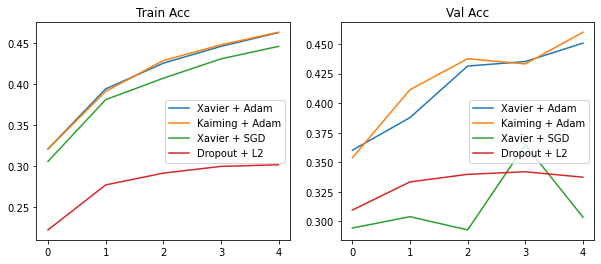

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 191ms/step


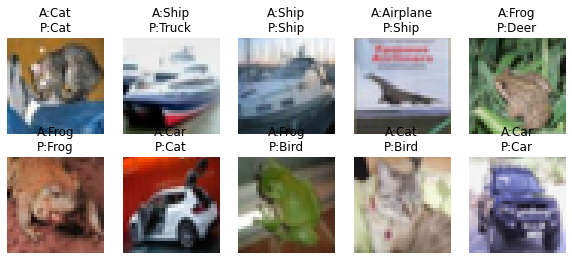

In [1]:
import tensorflow as tf
from tensorflow import keras
import numpy as np
import matplotlib.pyplot as plt

# 1. Load & Preprocess Data
(X_train, y_train), (X_test, y_test) = keras.datasets.cifar10.load_data()
X_test_imgs = X_test.copy()  # Keep unflattened images for plotting later

X_train = X_train.reshape(-1, 3072) / 255.0
X_test = X_test.reshape(-1, 3072) / 255.0
y_train, y_test = y_train.flatten(), y_test.flatten()

# 2. Build Model Function
def build_model(init, opt, drop=0, reg=0):
    layers = [keras.layers.Input(shape=(3072,))]
    for units in [512, 256, 128]:
        layers.append(keras.layers.Dense(
            units, activation='relu',
            kernel_initializer=init,
            kernel_regularizer=keras.regularizers.l2(reg) if reg else None
        ))
        if drop:
            layers.append(keras.layers.Dropout(drop))
    layers.append(keras.layers.Dense(10, activation='softmax'))
    
    model = keras.Sequential(layers)
    model.compile(optimizer=opt, loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

# 3. Train & Evaluate All 4 Configurations
experiments = [
    ("Xavier + Adam", "glorot_uniform", "adam", 0, 0),
    ("Kaiming + Adam", "he_normal", "adam", 0, 0),
    ("Xavier + SGD", "glorot_uniform", "sgd", 0, 0),
    ("Dropout + L2", "glorot_uniform", "adam", 0.3, 0.001)
]

histories, models, best_acc, best_model = {}, {}, 0, None

for name, init, opt, drop, reg in experiments:
    model = build_model(init, opt, drop, reg)
    histories[name] = model.fit(X_train, y_train, epochs=5, batch_size=64, validation_split=0.1, verbose=0)
    _, acc = model.evaluate(X_test, y_test, verbose=0)
    print(f"{name}: {acc*100:.2f}%")
    if acc > best_acc:
        best_acc, best_model = acc, model

# 4. Plot Training & Validation Accuracy
plt.figure(figsize=(10, 4))
for i, (metric, title) in enumerate([('accuracy', 'Train Acc'), ('val_accuracy', 'Val Acc')], 1):
    plt.subplot(1, 2, i)
    for name, h in histories.items():
        plt.plot(h.history[metric], label=name)
    plt.title(title)
    plt.legend()
plt.show()

# 5. Actual vs Predicted (First 10 Images)
classes = ['Airplane', 'Car', 'Bird', 'Cat', 'Deer', 'Dog', 'Frog', 'Horse', 'Ship', 'Truck']
preds = np.argmax(best_model.predict(X_test[:10]), axis=1)

plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test_imgs[i])
    plt.title(f"A:{classes[y_test[i]]}\nP:{classes[preds[i]]}")
    plt.axis('off')
plt.show()